In [1]:
'''Calculate, interpret, and balance precision, recall, and F1-scores across multiple thresholds and classes, 
tailoring evaluation metrics to the business context (e.g., high recall vs. high precision).'''

'Calculate, interpret, and balance precision, recall, and F1-scores across multiple thresholds and classes, \ntailoring evaluation metrics to the business context (e.g., high recall vs. high precision).'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
# load dataset
df = pd.read_csv("global_pharmacy_sales_data.csv")

# define target
target = "covid_flag"

# remove date-related columns
X = df.drop(columns=[target, "date", "year", "month", "day"], errors="ignore")
y = df[target]

# identify feature types automatically
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [4]:
# preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [5]:
# define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# train models
trained_models = {}
probabilities = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline
    probabilities[name] = pipeline.predict_proba(X_test)[:, 1]

print("all models trained successfully")

all models trained successfully


In [6]:
# evaluate multiple thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for name, probs in probabilities.items():

    for threshold in thresholds:

        # convert probabilities into predictions
        predictions = (probs >= threshold).astype(int)

        # calculate metrics
        precision = precision_score(y_test, predictions, zero_division=0)
        recall = recall_score(y_test, predictions, zero_division=0)
        f1 = f1_score(y_test, predictions, zero_division=0)

        results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

metrics_df = pd.DataFrame(results)

display(metrics_df.round(4))

,Model,Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.10,0.3335,1.0000,0.5002
1,Logistic Regression,0.15,0.3348,1.0000,0.5016
2,Logistic Regression,0.20,0.3511,0.9988,0.5196
3,Logistic Regression,0.25,0.3814,0.9796,0.5490
4,Logistic Regression,0.30,0.4201,0.9358,0.5799
5,Logistic Regression,0.35,0.4653,0.8756,0.6077
6,Logistic Regression,0.40,0.5075,0.8102,0.6241
7,Logistic Regression,0.45,0.5462,0.7410,0.6289
8,Logistic Regression,0.50,0.5837,0.6571,0.6182
9,Logistic Regression,0.55,0.6228,0.5777,0.5994


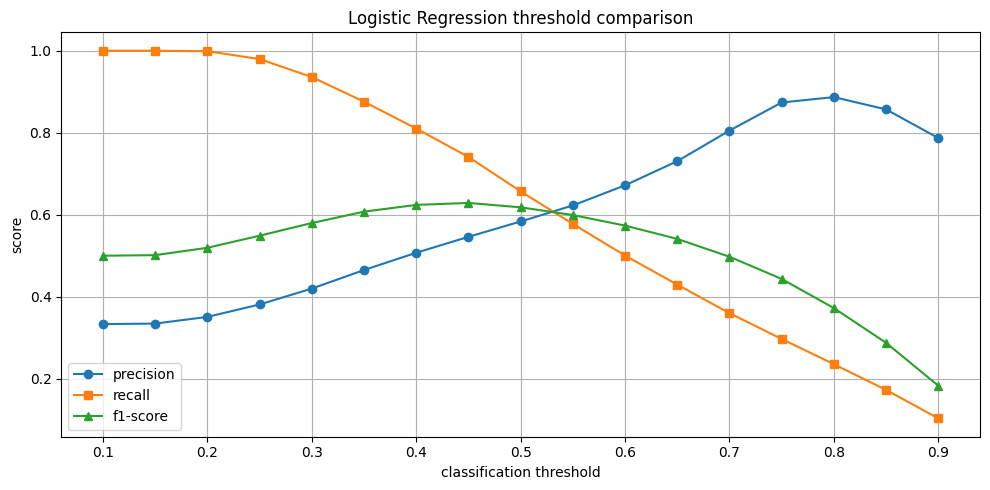

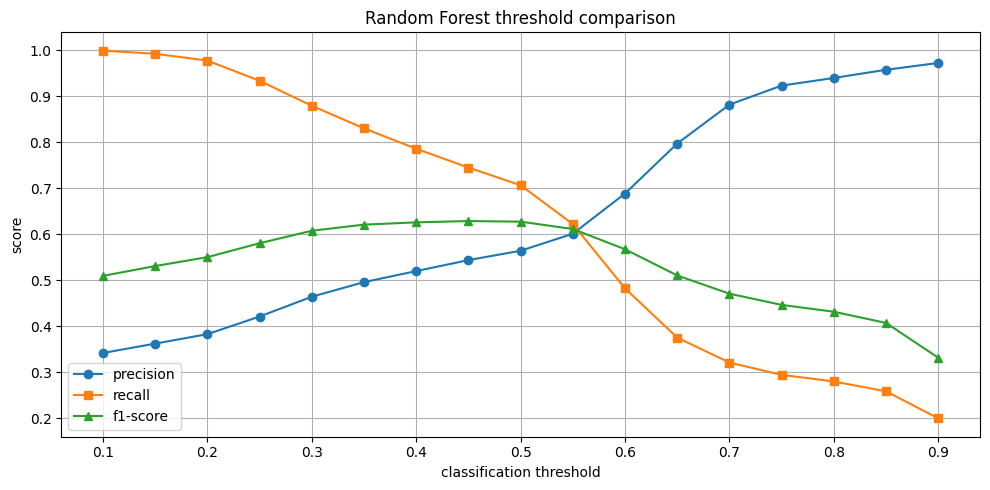

In [7]:
# compare metrics across thresholds
for model_name in metrics_df["Model"].unique():

    model_data = metrics_df[
        metrics_df["Model"] == model_name
    ]

    plt.figure(figsize=(10,5))

    plt.plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="o",
        label="precision"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="s",
        label="recall"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["F1 Score"],
        marker="^",
        label="f1-score"
    )

    plt.title(f"{model_name} threshold comparison")
    plt.xlabel("classification threshold")
    plt.ylabel("score")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [8]:
# select the highest f1-score threshold
best_thresholds = []

for model_name in metrics_df["Model"].unique():

    model_data = metrics_df[
        metrics_df["Model"] == model_name
    ]

    best = model_data.loc[
        model_data["F1 Score"].idxmax()
    ]

    best_thresholds.append(best)

best_df = pd.DataFrame(best_thresholds)

print("best balanced thresholds")

display(best_df.round(4))

best balanced thresholds


,Model,Threshold,Precision,Recall,F1 Score
7,Logistic Regression,0.45,0.5462,0.7410,0.6289
24,Random Forest,0.45,0.5438,0.7449,0.6286


In [10]:
# interpret threshold selection
for _, row in best_df.iterrows():


    print("model:", row["Model"])
    print("recommended threshold:", round(row["Threshold"], 2))
    print("precision:", round(row["Precision"], 4))
    print("recall:", round(row["Recall"], 4))
    print("f1-score:", round(row["F1 Score"], 4))

    print("\nmetric interpretation:")

    if row["Recall"] > row["Precision"]:
        print("- this threshold prioritizes recall.")
        print("- suitable when missing positive cases is more costly.")

    elif row["Precision"] > row["Recall"]:
        print("- this threshold prioritizes precision.")
        print("- suitable when false positive predictions are more costly.")

    else:
        print("- this threshold provides a balanced trade-off.")

    print("- the selected threshold maximizes the overall balance between precision and recall.")

model: Logistic Regression
recommended threshold: 0.45
precision: 0.5462
recall: 0.741
f1-score: 0.6289

metric interpretation:
- this threshold prioritizes recall.
- suitable when missing positive cases is more costly.
- the selected threshold maximizes the overall balance between precision and recall.
model: Random Forest
recommended threshold: 0.45
precision: 0.5438
recall: 0.7449
f1-score: 0.6286

metric interpretation:
- this threshold prioritizes recall.
- suitable when missing positive cases is more costly.
- the selected threshold maximizes the overall balance between precision and recall.


In [12]:
# generate class-wise evaluation reports
for _, row in best_df.iterrows():

    model_name = row["Model"]
    threshold = row["Threshold"]

    preds = (
        probabilities[model_name] >= threshold
    ).astype(int)

    print(f"class-wise evaluation: {model_name}")

    print(
        classification_report(
            y_test,
            preds,
            target_names=["negative", "positive"],
            zero_division=0
        )
    )

class-wise evaluation: Logistic Regression
              precision    recall  f1-score   support

    negative       0.84      0.69      0.76     23725
    positive       0.55      0.74      0.63     11873

    accuracy                           0.71     35598
   macro avg       0.69      0.72      0.69     35598
weighted avg       0.74      0.71      0.72     35598

class-wise evaluation: Random Forest
              precision    recall  f1-score   support

    negative       0.84      0.69      0.76     23725
    positive       0.54      0.74      0.63     11873

    accuracy                           0.71     35598
   macro avg       0.69      0.72      0.69     35598
weighted avg       0.74      0.71      0.71     35598

